In [ ]:
%pip install tensorflow matplotlib numpy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

dataset_path = Path(
    r"C:\Users\prama\Downloads\project\survillenceimagesexpanded"
)

print("TensorFlow version:", tf.__version__)
print("Dataset exists:", dataset_path.exists())

if not dataset_path.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {dataset_path}"
    )

TensorFlow version: 2.21.0
Dataset exists: True


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.3,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=16,
    label_mode="int"
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

if len(class_names) != 3:
    raise ValueError(
        f"Expected 3 class folders, but found: {class_names}"
    )

Found 1049 files belonging to 3 classes.
Using 735 files for training.
Classes: ['dangerimagesexpanded', 'isolatedimagesexpanded', 'safeimagesexpanded']
Number of classes: 3


In [4]:
val_test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.3,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=16,
    label_mode="int"
)

total_batches = len(val_test_ds)
val_size = total_batches // 2

if val_size == 0 or val_size == total_batches:
    raise ValueError(
        "Not enough batches to create validation and test sets."
    )

val_ds = val_test_ds.take(val_size)
test_ds = val_test_ds.skip(val_size)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Found 1049 files belonging to 3 classes.
Using 314 files for validation.
Training batches: 46
Validation batches: 10
Testing batches: 10


In [5]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Dataset loading optimized.")

Dataset loading optimized.


In [6]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.2),
])

print("Data augmentation configured.")

Data augmentation configured.


In [7]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully.")
print("Pretrained layers frozen:", not base_model.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
MobileNetV2 loaded successfully.
Pretrained layers frozen: True


In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    tf.keras.layers.Lambda(preprocess_input),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 compiled successfully.")

MobileNetV2 compiled successfully.


In [10]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20


C:\Users\prama\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 255ms/step - accuracy: 0.4177 - loss: 1.2887 - val_accuracy: 0.4563 - val_loss: 1.0618
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 226ms/step - accuracy: 0.4844 - loss: 1.0625 - val_accuracy: 0.5813 - val_loss: 0.8334
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 227ms/step - accuracy: 0.5755 - loss: 0.9264 - val_accuracy: 0.6625 - val_loss: 0.7184
Epoch 4/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 227ms/step - accuracy: 0.5986 - loss: 0.8525 - val_accuracy: 0.6500 - val_loss: 0.6995
Epoch 5/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 224ms/step - accuracy: 0.6449 - loss: 0.7707 - val_accuracy: 0.7188 - val_loss: 0.6395
Epoch 6/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 227ms/step - accuracy: 0.6626 - loss: 0.7183 - val_accuracy: 0.7812 - val_loss: 0.5899
Epoch 7/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 227ms/step - accuracy: 0.7034 - loss: 0.6756 - val_accuracy: 0.7625 - val_loss: 0.5734
Epoch 8/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 225ms/step - accuracy: 0.6925 - loss: 0.6586 - val_accuracy: 0.743

In [11]:
model.save("mobilenetv2_expanded_dataset_initial.keras")

print("Initial MobileNetV2 model saved successfully!")

Initial MobileNetV2 model saved successfully!


In [12]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning configured.")

Fine-tuning configured.


In [13]:
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 17s 286ms/step - accuracy: 0.7891 - loss: 0.4770 - val_accuracy: 0.7937 - val_loss: 0.4842
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 251ms/step - accuracy: 0.8245 - loss: 0.4551 - val_accuracy: 0.8125 - val_loss: 0.4888
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 250ms/step - accuracy: 0.8354 - loss: 0.4065 - val_accuracy: 0.8062 - val_loss: 0.4772
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 252ms/step - accuracy: 0.8408 - loss: 0.3995 - val_accuracy: 0.8250 - val_loss: 0.4470
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 249ms/step - accuracy: 0.8531 - loss: 0.3784 - val_accuracy: 0.8250 - val_loss: 0.4364
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 251ms/step - accuracy: 0.8653 - loss: 0.3658 - val_accuracy: 0.8313 - val_loss: 0.4675
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 252ms/step - accuracy: 0.8476 - loss: 0.3845 - val_accuracy: 0.8313 - val_loss: 0.4224
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 256ms/step - accuracy: 0.8707 - loss: 0.3330 - val_accu

In [14]:
finetuned_test_loss, finetuned_test_acc = model.evaluate(test_ds)

print("Fine-tuned Test Loss:", finetuned_test_loss)
print(
    f"Fine-tuned Test Accuracy: {finetuned_test_acc * 100:.2f}%"
)

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 166ms/step - accuracy: 0.8506 - loss: 0.4367
Fine-tuned Test Loss: 0.43670737743377686
Fine-tuned Test Accuracy: 85.06%


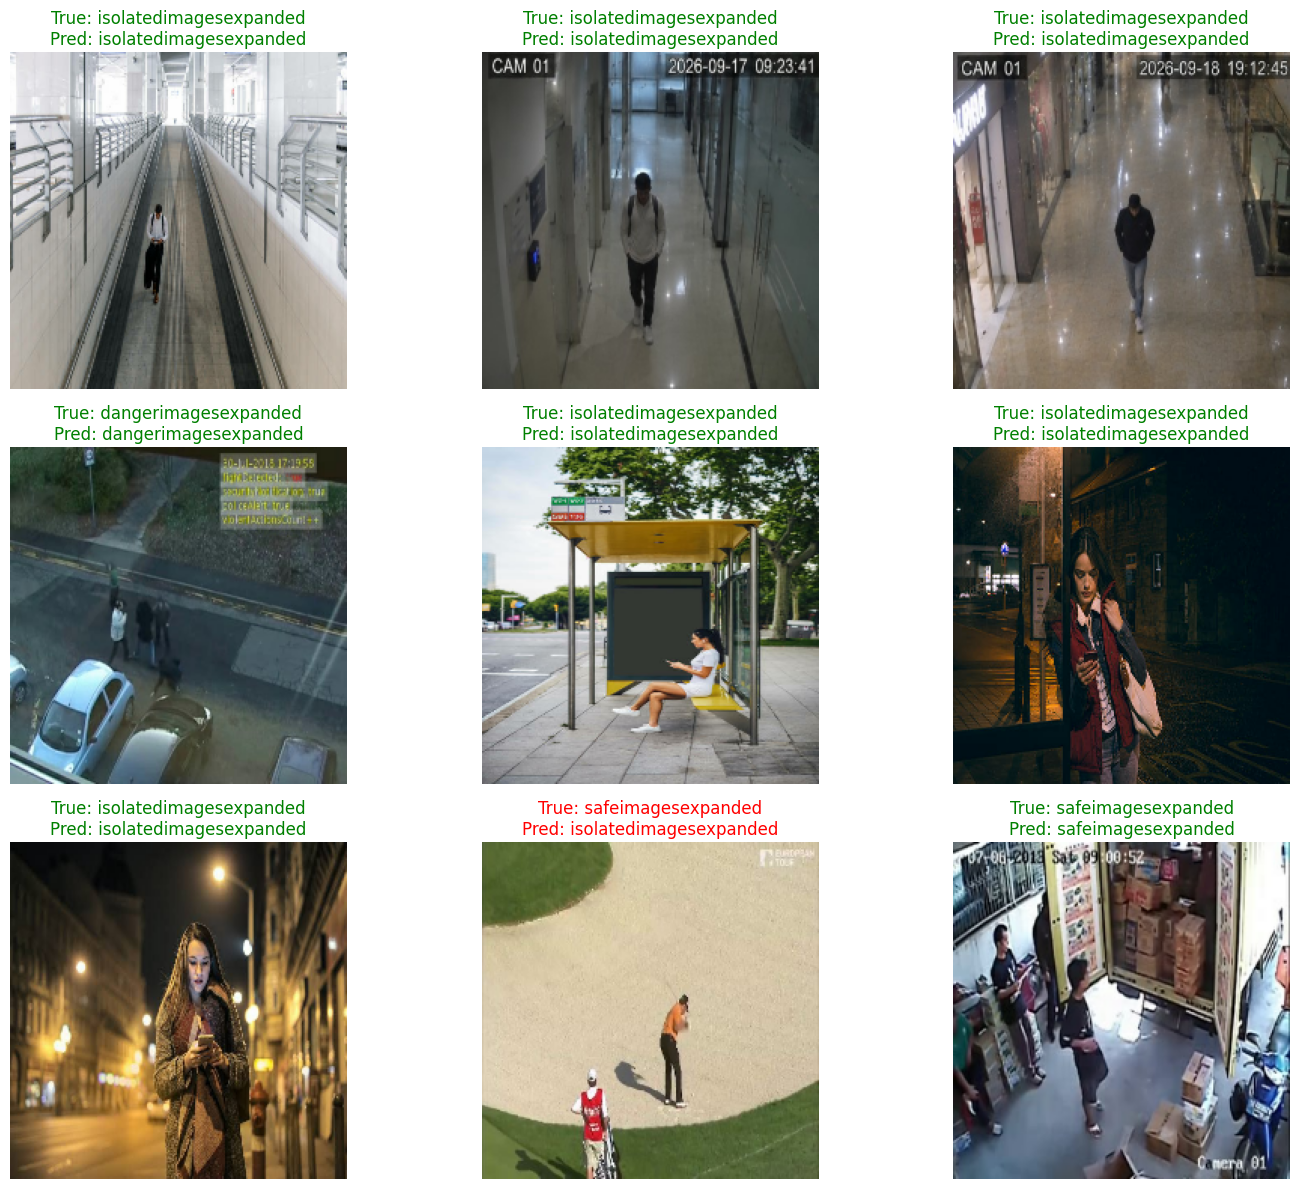

In [15]:
for images, labels in test_ds.take(1):
    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    num_images = min(9, len(images))

    plt.figure(figsize=(15, 12))

    for i in range(num_images):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        true_label = class_names[int(labels[i].numpy())]
        pred_label = class_names[int(predicted_labels[i])]

        color = "green" if true_label == pred_label else "red"

        plt.title(
            f"True: {true_label}\nPred: {pred_label}",
            color=color
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [18]:
print("Initial accuracy available:", "initial_test_acc" in globals())
print("Fine-tuned accuracy available:", "finetuned_test_acc" in globals())

Initial accuracy available: False
Fine-tuned accuracy available: True


In [21]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

initial_model = tf.keras.models.load_model(
    "mobilenetv2_expanded_dataset_initial.keras",
    custom_objects={"preprocess_input": preprocess_input},
    safe_mode=False
)

print("Initial model loaded successfully!")

Initial model loaded successfully!


In [22]:
initial_test_loss, initial_test_acc = initial_model.evaluate(test_ds)

print(f"Initial Test Accuracy: {initial_test_acc * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 186ms/step - accuracy: 0.7662 - loss: 0.5561
Initial Test Accuracy: 76.62%


In [ ]:
print("MobileNetV2 Results")
print(f"Initial Test Accuracy: {initial_test_acc * 100:.2f}%")
print(f"Fine-tuned Test Accuracy: {finetuned_test_acc * 100:.2f}%")

MobileNetV2 Results
Initial Test Accuracy: 76.62%
Fine-tuned Test Accuracy: 85.06%
